**2 SGD**

In [1]:
import numpy as np
import datasets
from sklearn.decomposition import PCA

# Cargar el dataset MNIST
ds = datasets.load_dataset("ylecun/mnist").with_format("numpy")

# Procesar los datos de entrenamiento
X_train = ds['train'][:]['image'].astype(np.float32).reshape(-1, 28 * 28) / 255.
y_train = ds['train'][:]['label'].astype(np.uint8)

# Procesar los datos de prueba
X_test = ds['test'][:]['image'].astype(np.float32).reshape(-1, 28 * 28) / 255.
y_test = ds['test'][:]['label'].astype(np.uint8)

# Aplicar PCA para reducción de dimensionalidad
K = 400
pca = PCA(n_components=K)
X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)

# Mostrar las dimensiones resultantes
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(60000, 400) (60000,) (10000, 400) (10000,)


In [2]:
from sklearn.linear_model import LogisticRegression
acc = LogisticRegression(C=0.1, max_iter=200).fit(X_train, y_train).score(X_test, y_test)
print(f"Precisión LogisticRegression: {acc:.1%}")

Precisión LogisticRegression: 92.6%


In [3]:

from sklearn.linear_model import SGDClassifier
acc = SGDClassifier(loss='log_loss').fit(X_train, y_train).score(X_test, y_test)
print(f"Precisión SGDClassifier: {acc:.1%}")


Precisión SGDClassifier: 91.9%


**Ejercicio**: compara LogisticRegression y SGDClassifier en Fashion-MNIST con $k = 600$ y CIFAR-10 con $K = 1000$


Fashion MNIST

In [6]:
import numpy as np
import datasets
from sklearn.decomposition import PCA

# Cargar el dataset MNIST
ds = datasets.load_dataset("zalando-datasets/fashion_mnist").with_format("numpy")

# Procesar los datos de entrenamiento
X_train = ds['train'][:]['image'].astype(np.float32).reshape(-1, 28 * 28) / 255.
y_train = ds['train'][:]['label'].astype(np.uint8)

# Procesar los datos de prueba
X_test = ds['test'][:]['image'].astype(np.float32).reshape(-1, 28 * 28) / 255.
y_test = ds['test'][:]['label'].astype(np.uint8)

# Aplicar PCA para reducción de dimensionalidad
K = 600
pca = PCA(n_components=K)
X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)

# Mostrar las dimensiones resultantes
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(60000, 600) (60000,) (10000, 600) (10000,)


In [7]:
from sklearn.linear_model import LogisticRegression
acc = LogisticRegression(C=0.1, max_iter=200).fit(X_train, y_train).score(X_test, y_test)
print(f"Precisión LogisticRegression: {acc:.1%}")

from sklearn.linear_model import SGDClassifier
acc = SGDClassifier(loss='log_loss').fit(X_train, y_train).score(X_test, y_test)
print(f"Precisión SGDClassifier: {acc:.1%}")


c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Precisión LogisticRegression: 84.5%
Precisión SGDClassifier: 84.0%


CIFAR-10

In [10]:
import numpy as np
import datasets
from sklearn.decomposition import PCA

# Cargar el dataset MNIST
ds = datasets.load_dataset("uoft-cs/cifar10").with_format("numpy")

# Procesar los datos de entrenamiento
X_train = ds['train'][:]['img'].astype(np.float32).reshape(-1, 32*32*3) / 255.
y_train = ds['train'][:]['label'].astype(np.uint8)

# Procesar los datos de prueba
X_test = ds['test'][:]['img'].astype(np.float32).reshape(-1, 32*32*3) / 255.
y_test = ds['test'][:]['label'].astype(np.uint8)

# Aplicar PCA para reducción de dimensionalidad
K = 1000
pca = PCA(n_components=K)
X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)

# Mostrar las dimensiones resultantes
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(50000, 1000) (50000,) (10000, 1000) (10000,)


In [11]:
from sklearn.linear_model import LogisticRegression
acc = LogisticRegression(C=0.1, max_iter=200).fit(X_train, y_train).score(X_test, y_test)
print(f"Precisión LogisticRegression: {acc:.1%}")

from sklearn.linear_model import SGDClassifier
acc = SGDClassifier(loss='log_loss').fit(X_train, y_train).score(X_test, y_test)
print(f"Precisión SGDClassifier: {acc:.1%}")


c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Precisión LogisticRegression: 40.5%
Precisión SGDClassifier: 37.3%


va mejor regrsion logistica

cada vez hay ds parametros (C- parametro de regularización, y max_iter) que hay que ajustar

.fit entrena un modelo, y en este esta probando todos los valores a brute force.

traspas - añade dos muestras C grande no mucha regularzacion y si C pequeño, mas regularzacion 

regularzacion - evitar overfitting


ajustas el C con validacion pq es como hacer trampa ya que memorza los datos. con los datos de validacion puedes hacer unos pruebas que no afectan el entrenamiento
----luego lo reentrenas con todo para no desaprovechar datos 

In [24]:

import numpy as np; import datasets; from sklearn.decomposition import PCA
ds = datasets.load_dataset("ylecun/mnist").with_format("numpy")
X_train = ds['train'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_train = ds['train'][:]['label'].astype(np.uint8)
X_test = ds['test'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_test = ds['test'][:]['label'].astype(np.uint8)
K = 400; pca = PCA(n_components=K); X_train = pca.fit_transform(X_train); X_test = pca.transform(X_test)



In [25]:

from sklearn.model_selection import train_test_split; from sklearn.linear_model import LogisticRegression
X_tr2, X_valid, y_tr2, y_valid = train_test_split(X_train, y_train, test_size=0.25, random_state=23)
Cs = np.array([.01, .02, .05, .1, .2, .5, 1, 2, 5, 10]); acc = np.zeros_like(Cs)
for i, C in enumerate(Cs): acc[i] = LogisticRegression(C=C, max_iter=200).fit(X_tr2, y_tr2).score(X_valid, y_valid)


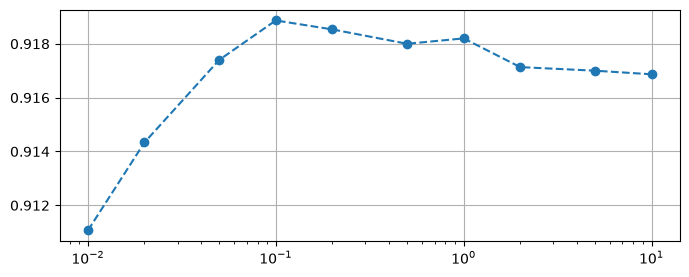

In [26]:
# Graficar los resultados de precisión según el hiperparámetro C
import matplotlib.pyplot as plt; plt.figure(figsize=(8, 3)); plt.grid(); plt.semilogx(Cs, acc, 'o--');


In [ ]:
# evaluación en test tras entrenar con todo el train y el C mejor hallado

C_star=.1; acc = LogisticRegression(C=C_star, max_iter=200).fit(X_train, y_train).score(X_test, y_test)
print(f"Precisión LogisticRegression con C = {C_star}: {acc:.1%}")


Precisión LogisticRegression con C = 0.1: 92.6%


hacer lo mimsmo con MNIST

In [28]:
import numpy as np; import datasets; from sklearn.decomposition import PCA
ds = datasets.load_dataset("zalando-datasets/fashion_mnist").with_format("numpy")
X_train = ds['train'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_train = ds['train'][:]['label'].astype(np.uint8)
X_test = ds['test'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_test = ds['test'][:]['label'].astype(np.uint8)
K = 600; pca = PCA(n_components=K); X_train = pca.fit_transform(X_train); X_test = pca.transform(X_test)


In [29]:

from sklearn.model_selection import train_test_split; from sklearn.linear_model import LogisticRegression
X_tr2, X_valid, y_tr2, y_valid = train_test_split(X_train, y_train, test_size=0.25, random_state=23)
Cs = np.array([.01, .02, .05, .1, .2, .5, 1, 2, 5, 10]); acc = np.zeros_like(Cs)
for i, C in enumerate(Cs): acc[i] = LogisticRegression(C=C, max_iter=200).fit(X_tr2, y_tr2).score(X_valid, y_valid)

c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/pre

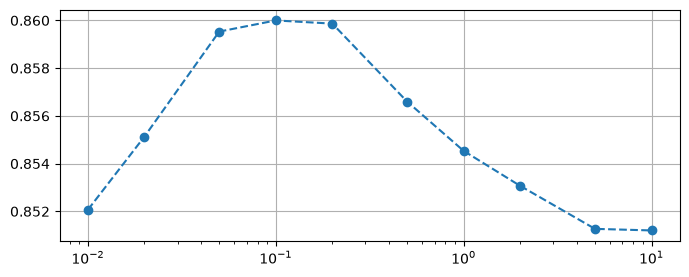

In [30]:
import matplotlib.pyplot as plt; plt.figure(figsize=(8, 3)); plt.grid(); plt.semilogx(Cs, acc, 'o--');


In [31]:
# evaluación en test tras entrenar con todo el train y el C mejor hallado

C_star=.1; acc = LogisticRegression(C=C_star, max_iter=200).fit(X_train, y_train).score(X_test, y_test)
print(f"Precisión LogisticRegression con C = {C_star}: {acc:.1%}")

Precisión LogisticRegression con C = 0.1: 84.5%


c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


con cifar 10

In [32]:
import numpy as np; import datasets; from sklearn.decomposition import PCA
ds = datasets.load_dataset("uoft-cs/cifar10").with_format("numpy")
X_train = ds['train'][:]['img'].astype(np.float32).reshape(-1, 32*32*3) / 255.
y_train = ds['train'][:]['label'].astype(np.uint8)
X_test = ds['test'][:]['img'].astype(np.float32).reshape(-1, 32*32*3) / 255.
y_test = ds['test'][:]['label'].astype(np.uint8)
K = 1000; pca = PCA(n_components=K); X_train = pca.fit_transform(X_train); X_test = pca.transform(X_test)


In [33]:

from sklearn.model_selection import train_test_split; from sklearn.linear_model import LogisticRegression
X_tr2, X_valid, y_tr2, y_valid = train_test_split(X_train, y_train, test_size=0.25, random_state=23)
Cs = np.array([.01, .02, .05, .1, .2, .5, 1, 2, 5, 10]); acc = np.zeros_like(Cs)
for i, C in enumerate(Cs): acc[i] = LogisticRegression(C=C, max_iter=200).fit(X_tr2, y_tr2).score(X_valid, y_valid)

c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/pre

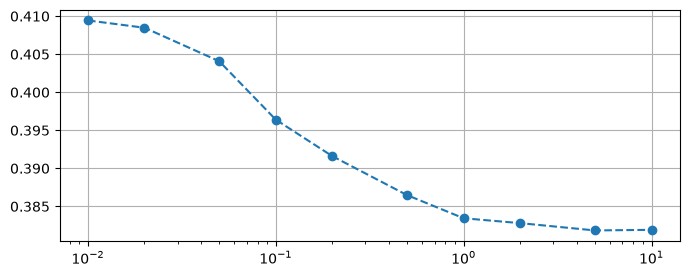

In [34]:
import matplotlib.pyplot as plt; plt.figure(figsize=(8, 3)); plt.grid(); plt.semilogx(Cs, acc, 'o--');


In [35]:
# evaluación en test tras entrenar con todo el train y el C mejor hallado

C_star=.1; acc = LogisticRegression(C=C_star, max_iter=200).fit(X_train, y_train).score(X_test, y_test)
print(f"Precisión LogisticRegression con C = {C_star}: {acc:.1%}")

Precisión LogisticRegression con C = 0.1: 40.4%


c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
